# Notatnik 12 — Final Model Comparison & Publication Tables

**Cel:** przygotowanie weryfikowalnych tabel i wykresów z eksperymentów **08b, 09, 10b i 11** bez ponownego trenowania modeli.

- **08b (obowiązkowy)**: dzienne prognozy OOS modeli ML i etykiety przyszłych spadków.
- **09 (opcjonalny)**: ablation study, porównania ΔAP i bootstrap z wcześniejszego eksperymentu.
- **10b (opcjonalny)**: ocena alarmów event-based; jej okno testowe to zwykle **2022–2024**, nie 2021–2024.
- **11 (opcjonalny)**: analiza filtracji LPPLS względem historycznych epizodów **UNION** (retrospektywna, nie predykcyjna).

**Zasady:** porównuj modele na tych samych datach, nie uśredniaj AP ani F1 rocznych zwykłą średnią, nie dobieraj najlepszego modelu na podstawie lat już analizowanych, nie nazywaj przedziałów bootstrapowych „dowodem istotności”.

Pliki źródłowe nie mogą pochodzić z eksperymentów syntetycznych lub testowych. Własne dane BTC z 08b muszą być przygotowane wcześniej.

## 0. Struktura katalogów

```text
Projekt/
  12_Final_Model_Comparison_Publication_Tables.ipynb
  wyniki_tuning_08b/
    08b_04_predykcje_OOS.csv       # obowiązkowe
  wyniki_ablation_09/
    09_08_ablation_AP_summary.csv  # opcjonalne
    09_09_ablation_step_deltas.csv # opcjonalne
  wyniki_threshold_10b/
    10b_07_wyniki_laczne_2022_2024.csv  # opcjonalne
    10b_02_wybrane_progi.csv       # opcjonalne
  wyniki_robustness_11/
    11_01_sensitivity_grid.csv     # opcjonalne
    11_09_refit_by_seed.csv        # opcjonalne
```

Przy braku plików opcjonalnych notatnik wykona dostępne sekcje i jawnie poinformuje o brakach. Jeśli brakuje 08b — zatrzyma się, zamiast tworzyć fikcyjne wyniki.

In [1]:
from pathlib import Path
import hashlib, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    average_precision_score, roc_auc_score, confusion_matrix
)
from IPython.display import display

ROOT = Path.cwd()
OUT = ROOT / "wyniki_finalne_12"
OUT.mkdir(exist_ok=True, parents=True)

# Nie wybieramy modelu po wynikach testu; to jedynie zakres wyświetlany na wykresach.
PLOT_DROP, PLOT_HORIZON = 10, 60
BOOT_REPS = 300  # finalna analiza odporności: 1000–2000 i różne długości bloku
BOOT_BLOCK_DAYS = 60
RANDOM_SEED = 42
MIN_VALID_BOOT_FRACTION = 0.75

def find_source(filename, folder, required=False):
    candidates = [ROOT / folder / filename, ROOT / filename]
    found = next((p for p in candidates if p.is_file()), None)
    if found is None and required:
        raise FileNotFoundError(
            f"Brak pliku {filename}. Uruchom właściwy notatnik. Szukano: {candidates}"
        )
    return found

SOURCES = {
    "08b_predictions": find_source("08b_04_predykcje_OOS.csv", "wyniki_tuning_08b", True),
    "09_ablation": find_source("09_08_ablation_AP_summary.csv", "wyniki_ablation_09"),
    "09_ablation_steps": find_source("09_09_ablation_step_deltas.csv", "wyniki_ablation_09"),
    "09_bootstrap_previous": find_source("09_01_paired_AP_blockbootstrap.csv", "wyniki_ablation_09"),
    "10b_events": find_source("10b_07_wyniki_laczne_2022_2024.csv", "wyniki_threshold_10b"),
    "10b_selected": find_source("10b_02_wybrane_progi.csv", "wyniki_threshold_10b"),
    "11_sensitivity": find_source("11_01_sensitivity_grid.csv", "wyniki_robustness_11"),
    "11_refit_seeds": find_source("11_09_refit_by_seed.csv", "wyniki_robustness_11"),
}

def checksum(path):
    h = hashlib.sha256()
    with path.open("rb") as fh:
        for chunk in iter(lambda: fh.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

manifest = pd.DataFrame([
    {"source": k, "available": p is not None,
     "path": str(p) if p is not None else "",
     "sha256": checksum(p) if p is not None else ""}
    for k, p in SOURCES.items()
])
manifest.to_csv(OUT / "12_00_manifest_zrodel.csv", index=False)
display(manifest[["source", "available", "path"]])

,source,available,path
0,08b_predictions,True,c:\Users\cynar\Desktop\projects\lppls_article\...
1,09_ablation,True,c:\Users\cynar\Desktop\projects\lppls_article\...
2,09_ablation_steps,True,c:\Users\cynar\Desktop\projects\lppls_article\...
3,09_bootstrap_previous,True,c:\Users\cynar\Desktop\projects\lppls_article\...
4,10b_events,True,c:\Users\cynar\Desktop\projects\lppls_article\...
5,10b_selected,True,c:\Users\cynar\Desktop\projects\lppls_article\...
6,11_sensitivity,True,c:\Users\cynar\Desktop\projects\lppls_article\...
7,11_refit_seeds,False,


## 1. Kontrola i standaryzacja prognoz 08b

Zawsze sprawdzamy, czy modele przewidują te same etykiety dla tej samej daty i zadania oraz czy `score` mieści się w [0, 1]. Nie wolno łączyć prognoz z różnymi definicjami targetu.

In [2]:
preds = pd.read_csv(SOURCES["08b_predictions"])
required = {"date", "year", "drop_pct", "horizon", "model", "feature_group", "y_true", "score"}
missing = required - set(preds.columns)
if missing:
    raise ValueError(f"08b_04_predykcje_OOS.csv — brak kolumn: {sorted(missing)}")

preds["date"] = pd.to_datetime(preds["date"], utc=True).dt.tz_convert(None).dt.normalize()
for col in ["year", "drop_pct", "horizon", "y_true"]:
    preds[col] = pd.to_numeric(preds[col], errors="raise").astype(int)
preds["score"] = pd.to_numeric(preds["score"], errors="raise")
if "y_pred" in preds:
    preds["y_pred"] = pd.to_numeric(preds["y_pred"], errors="raise").astype(int)
else:
    warnings.warn("Brak y_pred: metryki zależne od progu będą niedostępne; nie zastępujemy oryginalnego progu progiem 0.5.")

key = ["date", "drop_pct", "horizon", "model", "feature_group"]
if preds.duplicated(key).any():
    raise ValueError("Zduplikowane prognozy dla tego samego dnia/modelu/zestawu cech.")
if preds[["date", "model", "feature_group", "score"]].isna().any().any():
    raise ValueError("Brakujące daty/model/feature_group/score.")
if not preds["score"].between(0, 1).all():
    raise ValueError("Wartości score są poza [0,1].")
if not preds["y_true"].isin([0, 1]).all():
    raise ValueError("Etykiety muszą być binarne.")
if "y_pred" in preds and not preds["y_pred"].isin([0, 1]).all():
    raise ValueError("y_pred musi być binarne.")
if not preds["year"].eq(preds["date"].dt.year).all():
    raise ValueError("Kolumna year jest niezgodna z datami.")
if preds.groupby(["drop_pct", "horizon", "date"])["y_true"].nunique().gt(1).any():
    raise ValueError("Różne etykiety y_true dla tej samej daty i zadania!")

print("Wiersze:", len(preds), "| unikalne dni:", preds["date"].nunique())
print("Konfiguracje targetu:", sorted(preds[["drop_pct", "horizon"]].drop_duplicates().itertuples(index=False, name=None)))
print("Modele:", sorted(preds["model"].unique()))
print("Grupy cech:", sorted(preds["feature_group"].unique()))
display(preds.head(5))

Wiersze: 229392 | unikalne dni: 1431
Konfiguracje targetu: [(10, 30), (10, 45), (10, 60), (15, 30), (15, 45), (15, 60), (20, 30), (20, 45), (20, 60)]
Modele: ['Always-positive', 'CI > 0', 'CI > 0.05', 'CatBoost', 'DecisionTree', 'LightGBM', 'LogisticRegression', 'XGBoost']
Grupy cech: ['Baseline', 'LPPLS-only', 'Price+LPPLS', 'Price-only']


,date,year,drop_pct,horizon,model,feature_group,y_true,y_pred,score
0,2021-01-01,2021,10,30,Always-positive,Baseline,0,1,1.0
1,2021-01-02,2021,10,30,Always-positive,Baseline,0,1,1.0
2,2021-01-03,2021,10,30,Always-positive,Baseline,0,1,1.0
3,2021-01-04,2021,10,30,Always-positive,Baseline,0,1,1.0
4,2021-01-05,2021,10,30,Always-positive,Baseline,1,1,1.0


## 2. Wspólne daty testowe — matched OOS cohort

**Nie porównujemy dwóch AP obliczonych na różnych podzbiorach dni.** Dla każdego zadania wybieramy wspólną część dat wszystkich dostępnych wariantów ML. W raporcie zapisujemy, ile dni odpadło. Warianty `Baseline` nie ograniczają przecięcia.

In [3]:
ml = preds.loc[preds["feature_group"].ne("Baseline")].copy()
if ml.empty:
    raise ValueError("Brak prognoz modeli ML w pliku 08b.")

matched_parts = []
cohort_rows = []
for (drop, horizon), part in ml.groupby(["drop_pct", "horizon"], sort=True):
    variants = part[["model", "feature_group"]].drop_duplicates()
    n_variants = len(variants)
    available = part.groupby("date").size()
    valid_dates = available.index[available.eq(n_variants)]
    clean = part[part["date"].isin(valid_dates)].copy()
    label_ref = part.drop_duplicates("date")["y_true"]
    n_raw_dates = part["date"].nunique()
    n_matched = len(valid_dates)
    if n_matched == 0:
        raise ValueError(f"Brak wspólnych dat dla targetu {drop}%/{horizon}d")
    if n_matched / n_raw_dates < 0.8:
        warnings.warn(f"{drop}%/{horizon}d: mniej niż 80% dni wspólnych dla wszystkich modeli")
    cohort_rows.append({
        "drop_pct": drop, "horizon": horizon,
        "n_models_groups": n_variants,
        "n_raw_dates": n_raw_dates,
        "n_common_dates": n_matched,
        "retained_fraction": n_matched / n_raw_dates,
        "positive_rate": clean.drop_duplicates("date")["y_true"].mean(),
        "first_date": valid_dates.min(), "last_date": valid_dates.max(),
    })
    matched_parts.append(clean)

matched = pd.concat(matched_parts, ignore_index=True)
matched = matched.sort_values(["drop_pct", "horizon", "date", "model", "feature_group"])
cohorts = pd.DataFrame(cohort_rows)
cohorts.to_csv(OUT / "12_01_wspolne_daty_OOS.csv", index=False)
display(cohorts.round(4))

,drop_pct,horizon,n_models_groups,n_raw_dates,n_common_dates,retained_fraction,positive_rate,first_date,last_date
0,10,30,15,1431,1431,1.0,0.3997,2021-01-01,2024-12-01
1,10,45,15,1416,1416,1.0,0.4922,2021-01-01,2024-11-16
2,10,60,15,1401,1401,1.0,0.5453,2021-01-01,2024-11-01
3,15,30,15,1431,1431,1.0,0.2390,2021-01-01,2024-12-01
4,15,45,15,1416,1416,1.0,0.3206,2021-01-01,2024-11-16
5,15,60,15,1401,1401,1.0,0.3847,2021-01-01,2024-11-01
6,20,30,15,1431,1431,1.0,0.1139,2021-01-01,2024-12-01
7,20,45,15,1416,1416,1.0,0.1801,2021-01-01,2024-11-16
8,20,60,15,1401,1401,1.0,0.2298,2021-01-01,2024-11-01


## 3. AP i inne metryki — wszystkie zadania, modele i grupy cech

Average Precision porównujemy z **positive rate** wyliczonym dla **tych samych dni testowych**. W latach z jedną klasą AP/ROC-AUC nie należy interpretować tak samo jak w latach z dwiema klasami.

In [4]:
def safe_metrics(frame):
    y = frame["y_true"].to_numpy(dtype=int)
    p = frame["score"].to_numpy(dtype=float)
    positives = int(y.sum())
    neg = int((1-y).sum())
    result = {
        "n_days": len(y), "n_positive": positives, "n_negative": neg,
        "positive_rate": float(y.mean()),
        "avg_precision": float(average_precision_score(y, p)) if positives > 0 else np.nan,
        "roc_auc": float(roc_auc_score(y, p)) if positives > 0 and neg > 0 else np.nan,
    }
    if "y_pred" in frame.columns:
        yh = frame["y_pred"].to_numpy(dtype=int)
        tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0,1]).ravel()
        result.update({
            "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
            "precision": tp/(tp+fp) if (tp+fp) else np.nan,
            "recall": tp/(tp+fn) if (tp+fn) else np.nan,
            "f1": (2*tp)/(2*tp+fp+fn) if (2*tp+fp+fn) else np.nan,
            "specificity": tn/(tn+fp) if (tn+fp) else np.nan,
            "time_in_alarm": float(yh.mean()),
        })
    return result

rows = []
for (d,h,model,grp), part in matched.groupby(
    ["drop_pct", "horizon", "model", "feature_group"], sort=True
):
    rows.append({"drop_pct":d,"horizon":h,"model":model,"feature_group":grp,**safe_metrics(part)})
model_metrics = pd.DataFrame(rows)
model_metrics["AP_minus_prevalence"] = model_metrics["avg_precision"] - model_metrics["positive_rate"]
model_metrics.to_csv(OUT / "12_02_finalne_metryki_OOS.csv", index=False)
display(model_metrics.loc[(model_metrics.drop_pct==PLOT_DROP)&(model_metrics.horizon==PLOT_HORIZON)].round(4))

# Tabela porównująca trzy zestawy cech tego samego algorytmu na tych samych dniach.
compare = model_metrics.pivot_table(
    index=["drop_pct","horizon","model","positive_rate","n_days"],
    columns="feature_group", values="avg_precision", aggfunc="first"
).reset_index()
compare.columns.name = None
for grp in ["Price-only", "LPPLS-only", "Price+LPPLS"]:
    if grp not in compare.columns:
        compare[grp] = np.nan
compare["delta_AP_hybrid_vs_price"] = compare["Price+LPPLS"] - compare["Price-only"]
compare.to_csv(OUT / "12_03_tabela_porownawcza_AP.csv", index=False)
display(compare.round(4))

,drop_pct,horizon,model,feature_group,n_days,n_positive,n_negative,positive_rate,avg_precision,roc_auc,TP,FP,FN,TN,precision,recall,f1,specificity,time_in_alarm,AP_minus_prevalence
30,10,60,CatBoost,LPPLS-only,1401,764,637,0.5453,0.5577,0.4874,762,636,2,1,0.5451,0.9974,0.7049,0.0016,0.9979,0.0124
31,10,60,CatBoost,Price+LPPLS,1401,764,637,0.5453,0.4983,0.4671,736,618,28,19,0.5436,0.9634,0.6950,0.0298,0.9665,-0.0471
32,10,60,CatBoost,Price-only,1401,764,637,0.5453,0.4836,0.4448,740,621,24,16,0.5437,0.9686,0.6965,0.0251,0.9714,-0.0617
33,10,60,DecisionTree,LPPLS-only,1401,764,637,0.5453,0.5142,0.3947,748,631,16,6,0.5424,0.9791,0.6981,0.0094,0.9843,-0.0311
34,10,60,DecisionTree,Price+LPPLS,1401,764,637,0.5453,0.5132,0.4689,597,475,167,162,0.5569,0.7814,0.6503,0.2543,0.7652,-0.0322
35,10,60,DecisionTree,Price-only,1401,764,637,0.5453,0.5198,0.4886,605,522,159,115,0.5368,0.7919,0.6399,0.1805,0.8044,-0.0255
36,10,60,LightGBM,LPPLS-only,1401,764,637,0.5453,0.5489,0.4824,758,634,6,3,0.5445,0.9921,0.7032,0.0047,0.9936,0.0036
37,10,60,LightGBM,Price+LPPLS,1401,764,637,0.5453,0.5221,0.4557,726,597,38,40,0.5488,0.9503,0.6957,0.0628,0.9443,-0.0232
38,10,60,LightGBM,Price-only,1401,764,637,0.5453,0.4591,0.4027,678,556,86,81,0.5494,0.8874,0.6787,0.1272,0.8808,-0.0862
39,10,60,LogisticRegression,LPPLS-only,1401,764,637,0.5453,0.5824,0.5702,760,634,4,3,0.5452,0.9948,0.7044,0.0047,0.9950,0.0370


,drop_pct,horizon,model,positive_rate,n_days,LPPLS-only,Price+LPPLS,Price-only,delta_AP_hybrid_vs_price
0,10,30,CatBoost,0.3997,1431,0.4017,0.3910,0.3789,0.0121
1,10,30,DecisionTree,0.3997,1431,0.4089,0.3856,0.3972,-0.0116
2,10,30,LightGBM,0.3997,1431,0.4121,0.4023,0.3735,0.0288
3,10,30,LogisticRegression,0.3997,1431,0.4242,0.3707,0.3592,0.0115
4,10,30,XGBoost,0.3997,1431,0.4052,0.3820,0.3642,0.0178
5,10,45,CatBoost,0.4922,1416,0.5032,0.4647,0.4254,0.0392
6,10,45,DecisionTree,0.4922,1416,0.4444,0.5127,0.5109,0.0018
7,10,45,LightGBM,0.4922,1416,0.5033,0.4807,0.4513,0.0293
8,10,45,LogisticRegression,0.4922,1416,0.5380,0.5251,0.5169,0.0082
9,10,45,XGBoost,0.4922,1416,0.5079,0.4472,0.4413,0.0058


## 4. Wykres AP z punktem odniesienia (częstość klasy pozytywnej)

Rysujemy baseline dla danego celu na tej samej kohorcie. Nie interpretujemy AP 0,58 jako dobrego wyniku bez porównania z positive rate.

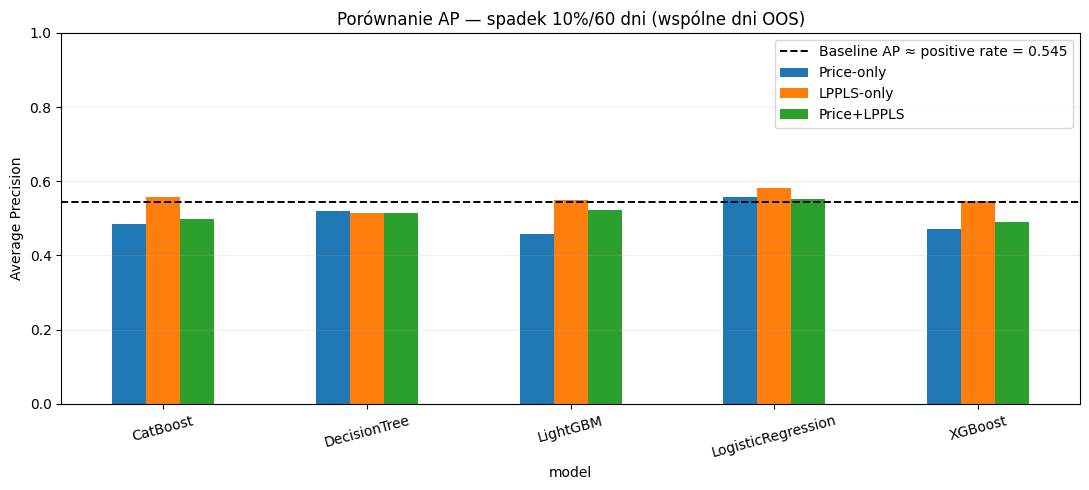

In [5]:
sub = model_metrics.loc[
    (model_metrics.drop_pct==PLOT_DROP) & (model_metrics.horizon==PLOT_HORIZON)
]
if not sub.empty:
    pivot = sub.pivot(index="model", columns="feature_group", values="avg_precision")
    cols = [x for x in ["Price-only","LPPLS-only","Price+LPPLS"] if x in pivot.columns]
    fig, ax = plt.subplots(figsize=(11,5))
    pivot[cols].plot(kind="bar", ax=ax, rot=15)
    baseline = float(sub.positive_rate.iloc[0])
    ax.axhline(baseline, color="black", linestyle="--", linewidth=1.4,
               label=f"Baseline AP ≈ positive rate = {baseline:.3f}")
    ax.set_ylabel("Average Precision")
    ax.set_ylim(0,1)
    ax.set_title(f"Porównanie AP — spadek {PLOT_DROP}%/{PLOT_HORIZON} dni (wspólne dni OOS)")
    ax.legend()
    ax.grid(axis="y",alpha=.2)
    fig.tight_layout()
    fig.savefig(OUT / "12_04_AP_vs_prevalence.png", dpi=200)
    plt.show()
else:
    print("Brak wybranej konfiguracji do wykresu, dostępne:", cohorts[["drop_pct","horizon"]].values.tolist())

## 5. Stabilność roczna

Wartość AP na poszczególnych latach podajemy osobno. **Nie uśredniamy** rocznych AP w celu uzyskania głównego wyniku: główna metryka jest wyliczona na połączonych, sparowanych prognozach dziennych.

,year,model,feature_group,n_positive,positive_rate,avg_precision
120,2021,CatBoost,LPPLS-only,264,0.723,0.695
121,2021,CatBoost,Price+LPPLS,264,0.723,0.600
122,2021,CatBoost,Price-only,264,0.723,0.603
123,2021,DecisionTree,LPPLS-only,264,0.723,0.708
124,2021,DecisionTree,Price+LPPLS,264,0.723,0.674
125,2021,DecisionTree,Price-only,264,0.723,0.673
126,2021,LightGBM,LPPLS-only,264,0.723,0.687
127,2021,LightGBM,Price+LPPLS,264,0.723,0.663
128,2021,LightGBM,Price-only,264,0.723,0.687
129,2021,LogisticRegression,LPPLS-only,264,0.723,0.688


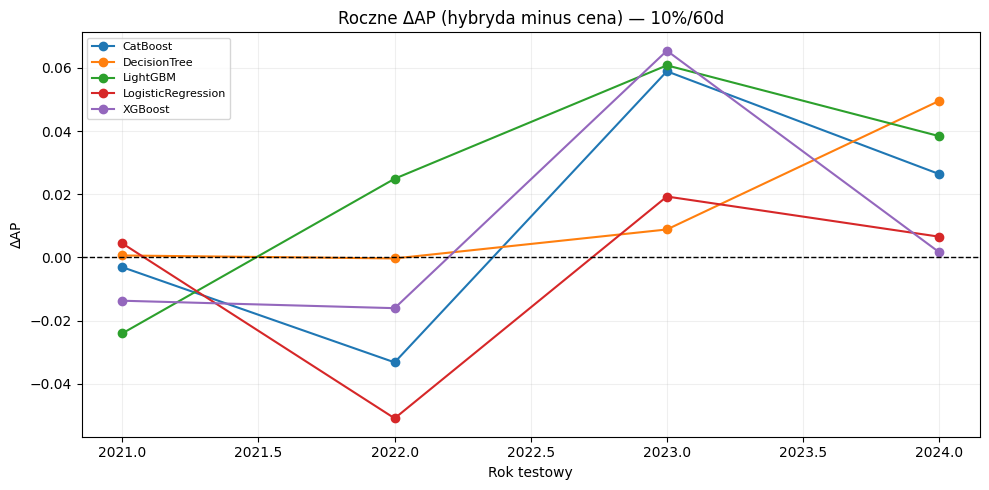

In [6]:
year_rows = []
for (d,h,year,model,grp), part in matched.groupby(
    ["drop_pct", "horizon", "year", "model", "feature_group"], sort=True
):
    year_rows.append({"drop_pct":d,"horizon":h,"year":year,"model":model,
                      "feature_group":grp,**safe_metrics(part)})
by_year = pd.DataFrame(year_rows)
by_year.to_csv(OUT / "12_05_metryki_roczne_OOS.csv", index=False)
display(by_year.loc[(by_year.drop_pct==PLOT_DROP)&(by_year.horizon==PLOT_HORIZON),
                    ["year","model","feature_group","n_positive","positive_rate","avg_precision"]].round(3))

# Porównania per rok model-po-modelu (AP może być nieokreślone bez pozytywnej klasy).
yearly_pivot = by_year.pivot_table(index=["drop_pct","horizon","year","model"],
                                 columns="feature_group",values="avg_precision",aggfunc="first").reset_index()
yearly_pivot.columns.name = None
if {"Price-only","Price+LPPLS"}.issubset(yearly_pivot.columns):
    yearly_pivot["delta_AP"] = yearly_pivot["Price+LPPLS"] - yearly_pivot["Price-only"]
    yearly_pivot.to_csv(OUT / "12_06_roczne_delta_AP.csv", index=False)
    view = yearly_pivot.loc[(yearly_pivot.drop_pct==PLOT_DROP)&(yearly_pivot.horizon==PLOT_HORIZON)]
    if not view.empty:
        fig, ax = plt.subplots(figsize=(10,5))
        for model, grp in view.groupby("model"):
            ax.plot(grp.year, grp.delta_AP, marker="o", label=model)
        ax.axhline(0,color="black",linestyle="--",linewidth=1)
        ax.set_title(f"Roczne ΔAP (hybryda minus cena) — {PLOT_DROP}%/{PLOT_HORIZON}d")
        ax.set_xlabel("Rok testowy"); ax.set_ylabel("ΔAP")
        ax.grid(alpha=.2); ax.legend(fontsize=8)
        fig.tight_layout()
        fig.savefig(OUT / "12_07_roczne_delta_AP.png",dpi=200)
        plt.show()

## 6. Sparowany bootstrap blokowy ΔAP

Ten sam resampling **dat** stosujemy jednocześnie do obu modeli. Resamplujemy bloki **wewnątrz poszczególnych lat testowych**, aby nie mieszać sztucznie granic lat. 95% przedział procentylowy jest **przybliżeniem niepewności**, nie uwzględnia wielokrotnego wyboru modeli i nie stanowi niezależnego potwierdzenia hipotez.

,drop_pct,horizon,model,n_common_days,positive_rate,AP_price,AP_hybrid,delta_AP,block_days,ci_low,ci_high,boot_valid,boot_reps
10,10,60,CatBoost,1401,0.5453,0.4836,0.4983,0.0147,60,-0.0077,0.0454,300,300
11,10,60,DecisionTree,1401,0.5453,0.5198,0.5132,-0.0067,60,-0.0441,0.0307,300,300
12,10,60,LightGBM,1401,0.5453,0.4591,0.5221,0.0630,60,0.0090,0.0999,300,300
13,10,60,LogisticRegression,1401,0.5453,0.5585,0.5534,-0.0050,60,-0.0237,0.0355,300,300
14,10,60,XGBoost,1401,0.5453,0.4715,0.4897,0.0182,60,-0.0000,0.0350,300,300


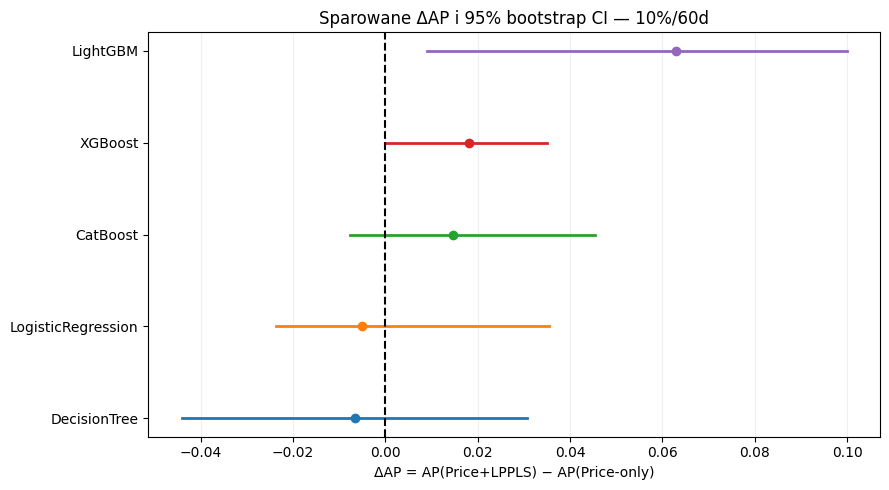

In [7]:
def bootstrap_paired_delta(pair, n_boot=BOOT_REPS, block_len=BOOT_BLOCK_DAYS, seed=RANDOM_SEED):
    pair = pair.sort_values("date").reset_index(drop=True)
    y = pair["y_true"].to_numpy(dtype=int)
    score_h = pair["hybrid"].to_numpy(dtype=float)
    score_p = pair["price"].to_numpy(dtype=float)
    if len(np.unique(y)) < 2:
        return {"ci_low":np.nan, "ci_high":np.nan, "boot_valid":0,"boot_reps":n_boot}
    years = pair["date"].dt.year.to_numpy()
    rng = np.random.default_rng(seed)
    groups = [np.flatnonzero(years==yr) for yr in sorted(set(years))]
    draws = []
    for _ in range(n_boot):
        sample = []
        for ids in groups:
            n = len(ids)
            block = min(block_len, n)
            sampled = []
            while len(sampled) < n:
                start = int(rng.integers(0, n-block+1))
                sampled.extend(ids[start:start+block].tolist())
            sample.extend(sampled[:n])
        sample = np.asarray(sample, dtype=int)
        yy = y[sample]
        if yy.min() == yy.max():
            continue
        diff = (average_precision_score(yy, score_h[sample]) -
                average_precision_score(yy, score_p[sample]))
        draws.append(diff)
    valid = len(draws)
    if valid < max(30, int(n_boot * MIN_VALID_BOOT_FRACTION)):
        return {"ci_low":np.nan,"ci_high":np.nan,"boot_valid":valid,"boot_reps":n_boot}
    return {"ci_low":float(np.quantile(draws,.025)),
            "ci_high":float(np.quantile(draws,.975)),
            "boot_valid":valid,"boot_reps":n_boot}

pair_rows=[]
for (d,h,model), part in matched.groupby(["drop_pct","horizon","model"],sort=True):
    score_wide = part.pivot(index="date",columns="feature_group",values="score")
    if not {"Price-only","Price+LPPLS"}.issubset(score_wide.columns):
        continue
    y = part.drop_duplicates("date").set_index("date")["y_true"]
    pair = score_wide[["Price-only","Price+LPPLS"]].join(y).dropna().reset_index()
    pair = pair.rename(columns={"Price-only":"price","Price+LPPLS":"hybrid"})
    if pair.empty or pair.y_true.sum() == 0:
        continue
    ap_price = average_precision_score(pair.y_true,pair.price)
    ap_hybrid = average_precision_score(pair.y_true,pair.hybrid)
    ci = bootstrap_paired_delta(pair,seed=RANDOM_SEED + int(d)*100 + int(h) + sum(map(ord,str(model))))
    pair_rows.append({"drop_pct":d,"horizon":h,"model":model,"n_common_days":len(pair),
                      "positive_rate":pair.y_true.mean(),"AP_price":ap_price,
                      "AP_hybrid":ap_hybrid,"delta_AP":ap_hybrid-ap_price,
                      "block_days":BOOT_BLOCK_DAYS,**ci})

paired = pd.DataFrame(pair_rows)
paired.to_csv(OUT / "12_08_paired_delta_AP_blockbootstrap.csv", index=False)
display(paired.loc[(paired.drop_pct==PLOT_DROP)&(paired.horizon==PLOT_HORIZON)].round(4))

v = paired.loc[(paired.drop_pct==PLOT_DROP)&(paired.horizon==PLOT_HORIZON)].sort_values("delta_AP")
if not v.empty:
    fig,ax = plt.subplots(figsize=(9,5))
    yloc = np.arange(len(v))
    for k, row in enumerate(v.itertuples()):
        ax.scatter(row.delta_AP, k, zorder=3)
        if pd.notna(row.ci_low) and pd.notna(row.ci_high):
            ax.plot([row.ci_low,row.ci_high],[k,k],linewidth=2)
    ax.axvline(0,color="black",linestyle="--")
    ax.set_yticks(yloc,v.model)
    ax.set_xlabel("ΔAP = AP(Price+LPPLS) − AP(Price-only)")
    ax.set_title(f"Sparowane ΔAP i 95% bootstrap CI — {PLOT_DROP}%/{PLOT_HORIZON}d")
    ax.grid(axis="x",alpha=.2)
    fig.tight_layout()
    fig.savefig(OUT / "12_09_delta_AP_z_CI.png",dpi=200)
    plt.show()

## 7. Wyniki ablation z notatnika 09 (opcjonalne)

Ablation w 09 korzysta z osobnych prognoz po odjęciu/dodaniu grup cech. Przedstawiamy ją oddzielnie; nie łączymy automatycznie z prognozami z 08b, ponieważ może mieć inne dostępne modele i zakres zadań.

,drop_pct,horizon,model,feature_group,n_days,positive_rate,AP,F1,TP,FP,FN,TN,AP_minus_prevalence
0,10,60,LogisticRegression,A_Price,1401,0.5453,0.5500,0.7052,763,637,1,0,0.0047
1,10,60,LogisticRegression,B_Price_CI,1401,0.5453,0.5546,0.7028,753,626,11,11,0.0093
2,10,60,LogisticRegression,C_Price_CI_m_w_tgap,1401,0.5453,0.5532,0.7042,750,616,14,21,0.0078
3,10,60,LogisticRegression,D_Price_CI_m_w_tgap_r2,1401,0.5453,0.5518,0.7058,764,637,0,0,0.0065
4,10,60,LogisticRegression,E_Price_AllLPPLS,1401,0.5453,0.5534,0.7055,763,636,1,1,0.0081
5,10,60,XGBoost,A_Price,1401,0.5453,0.4715,0.6884,718,604,46,33,-0.0739
6,10,60,XGBoost,B_Price_CI,1401,0.5453,0.4850,0.6937,719,590,45,47,-0.0603
7,10,60,XGBoost,C_Price_CI_m_w_tgap,1401,0.5453,0.4875,0.6915,716,591,48,46,-0.0578
8,10,60,XGBoost,D_Price_CI_m_w_tgap_r2,1401,0.5453,0.4911,0.6931,718,590,46,47,-0.0542
9,10,60,XGBoost,E_Price_AllLPPLS,1401,0.5453,0.4897,0.6938,715,582,49,55,-0.0557


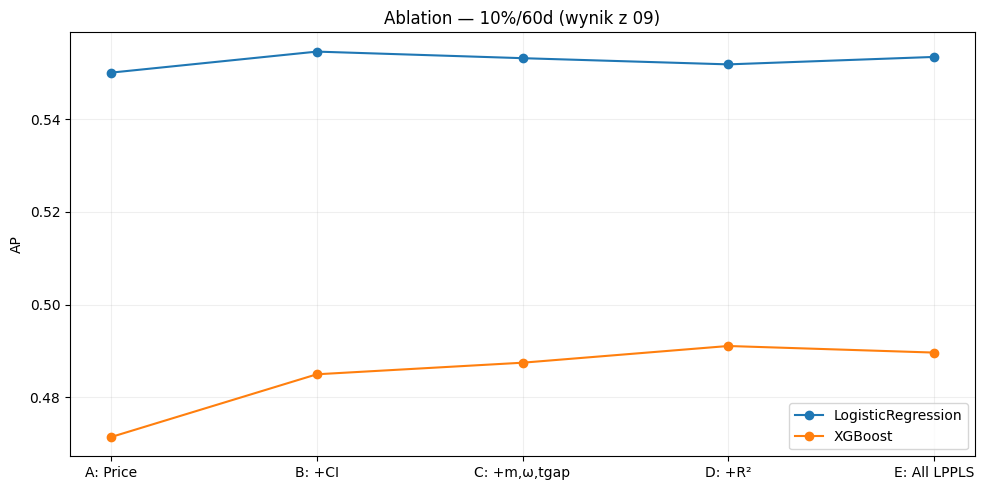

Zapisano wyniki krokowego ΔAP z 09.


In [8]:
if SOURCES["09_ablation"] is None:
    print("Brak 09_08_ablation_AP_summary.csv — pomijam ablation. Uruchom notebook 09 na rzeczywistym BTC.")
else:
    ablation = pd.read_csv(SOURCES["09_ablation"])
    need = {"drop_pct","horizon","model","feature_group","AP"}
    if not need.issubset(ablation.columns):
        raise ValueError("Nieznany format 09_08_ablation_AP_summary.csv: " + str(need - set(ablation.columns)))
    ablation.to_csv(OUT / "12_10_publikacja_ablation.csv",index=False)
    display(ablation.loc[(ablation.drop_pct==PLOT_DROP)&(ablation.horizon==PLOT_HORIZON)].round(4))
    av = ablation.loc[(ablation.drop_pct==PLOT_DROP)&(ablation.horizon==PLOT_HORIZON)]
    if not av.empty:
        order = ["A_Price","B_Price_CI","C_Price_CI_m_w_tgap","D_Price_CI_m_w_tgap_r2","E_Price_AllLPPLS"]
        fig,ax=plt.subplots(figsize=(10,5))
        for name,group in av.groupby("model"):
            g=group.set_index("feature_group").reindex(order)
            ax.plot(np.arange(len(order)),g.AP,marker="o",label=name)
        ax.set_xticks(np.arange(5),["A: Price","B: +CI","C: +m,ω,tgap","D: +R²","E: All LPPLS"])
        ax.set_ylabel("AP")
        ax.set_title(f"Ablation — {PLOT_DROP}%/{PLOT_HORIZON}d (wynik z 09)")
        ax.legend();ax.grid(alpha=.2)
        fig.tight_layout()
        fig.savefig(OUT / "12_11_ablation_z_09.png",dpi=200)
        plt.show()
    if SOURCES["09_ablation_steps"] is not None:
        steps = pd.read_csv(SOURCES["09_ablation_steps"])
        steps.to_csv(OUT / "12_12_ablation_krokowe_delta.csv",index=False)
        print("Zapisano wyniki krokowego ΔAP z 09.")

## 8. Metryki event-based z notatnika 10b (opcjonalne)

**Uwaga:** wynik 10b jest zwykle oceniany w okresie 2022–2024 i dotyczy przekroczenia progu drawdown względem lokalnego maksimum. **Nie porównujemy bezpośrednio** event recall z 10b z dziennym AP z 08b; to inne pytania badawcze.

Jeżeli próg był wybrany przy `insufficient_events_in_calibration` lub `infeasible_fallback`, odpowiednio oznaczamy jego status. Nie nazywamy takiego progu „zoptymalizowanym”.

,model,feature_group,strategy,event_recall_onset,false_warnings_per_year,time_in_alarm,calibration_statuses
0,LogisticRegression,Price-only,optimized_prior_OOS,0.286,1.280,0.042,"infeasible_fallback, insufficient_events_in_ca..."
1,LogisticRegression,Price-only,fixed_050,0.286,1.280,0.055,"infeasible_fallback, insufficient_events_in_ca..."
2,LogisticRegression,Price-only,fixed_075,0.000,0.000,0.000,"infeasible_fallback, insufficient_events_in_ca..."
3,LogisticRegression,Price-only,original_08b,0.000,1.280,0.997,"infeasible_fallback, insufficient_events_in_ca..."
4,LogisticRegression,LPPLS-only,optimized_prior_OOS,0.571,0.853,0.068,"feasible, insufficient_events_in_calibration"
5,LogisticRegression,LPPLS-only,fixed_050,0.429,0.853,0.078,"feasible, insufficient_events_in_calibration"
6,LogisticRegression,LPPLS-only,fixed_075,0.429,1.280,0.021,"feasible, insufficient_events_in_calibration"
7,LogisticRegression,LPPLS-only,original_08b,0.000,1.280,0.996,"feasible, insufficient_events_in_calibration"
8,LogisticRegression,Price+LPPLS,optimized_prior_OOS,0.429,1.280,0.106,"feasible, insufficient_events_in_calibration"
9,LogisticRegression,Price+LPPLS,fixed_050,0.429,1.280,0.106,"feasible, insufficient_events_in_calibration"


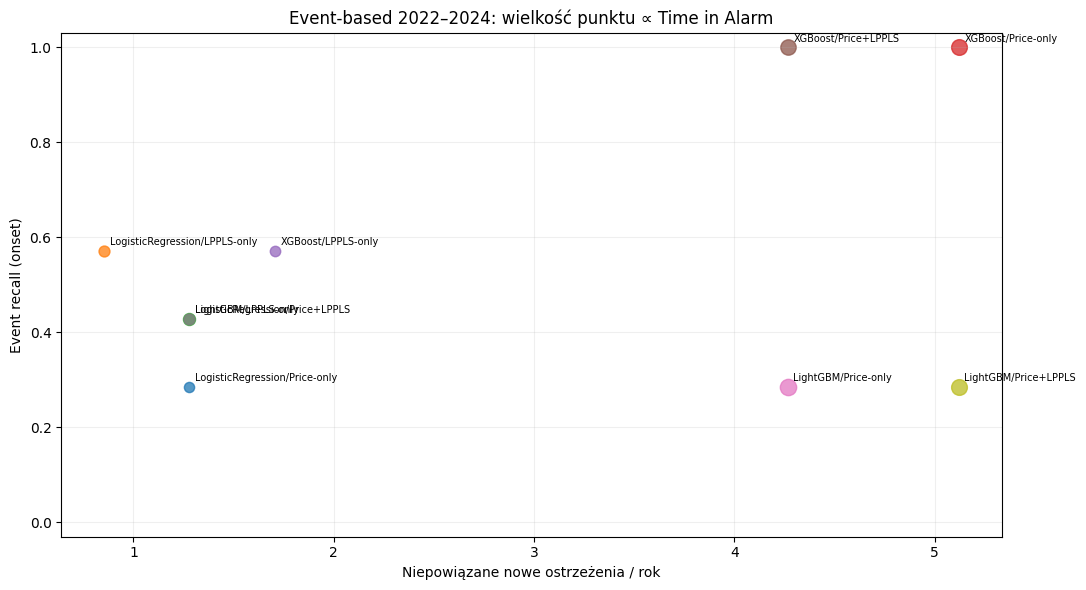

In [9]:
if SOURCES["10b_events"] is None:
    print("Brak 10b_07_wyniki_laczne_2022_2024.csv — pomijam event-based.")
else:
    events=pd.read_csv(SOURCES["10b_events"])
    required_ev={"drop_pct","horizon","model","feature_group","strategy","event_recall_onset",
                 "false_warnings_per_year","time_in_alarm"}
    if not required_ev.issubset(events):
        raise ValueError("Nieznany format 10b: "+str(required_ev-set(events)))
    keys=["drop_pct","horizon","model","feature_group"]
    if SOURCES["10b_selected"] is not None:
        chosen=pd.read_csv(SOURCES["10b_selected"])
        if set(keys+["selection_status"]).issubset(chosen.columns):
            status=(chosen.groupby(keys)["selection_status"]
                    .agg(lambda s:", ".join(sorted(set(s.dropna().astype(str)))))
                    .reset_index().rename(columns={"selection_status":"calibration_statuses"}))
            events=events.merge(status,on=keys,how="left",validate="many_to_one")
    if "calibration_statuses" not in events:
        events["calibration_statuses"]="brak szczegółowych danych o doborze progu"
    events["caution"] = np.where(
        events.strategy.eq("optimized_prior_OOS") &
        ~events.calibration_statuses.eq("feasible"),
        "DOBÓR PROGU: SPRAWDŹ STATUS", "")
    events.to_csv(OUT / "12_13_event_based_publikacja_2022_2024.csv",index=False)
    view=events.loc[(events.drop_pct==PLOT_DROP)&(events.horizon==PLOT_HORIZON)]
    showcols=["model","feature_group","strategy","event_recall_onset","false_warnings_per_year",
              "time_in_alarm","calibration_statuses"]
    display(view[showcols].round(3))
    v=view.loc[view.strategy.eq("optimized_prior_OOS")]
    if not v.empty:
        fig,ax=plt.subplots(figsize=(11,6))
        for r in v.itertuples():
            ax.scatter(r.false_warnings_per_year,r.event_recall_onset,
                       s=40+330*float(r.time_in_alarm),alpha=.75)
            ax.annotate(f"{r.model}/{r.feature_group}",
                        (r.false_warnings_per_year,r.event_recall_onset),
                        xytext=(4,4),textcoords="offset points",fontsize=7)
        ax.set_xlabel("Niepowiązane nowe ostrzeżenia / rok")
        ax.set_ylabel("Event recall (onset)")
        ax.set_ylim(-.03,1.03)
        ax.set_title("Event-based 2022–2024: wielkość punktu ∝ Time in Alarm")
        ax.grid(alpha=.2)
        fig.tight_layout()
        fig.savefig(OUT / "12_14_event_recall_false_warnings.png",dpi=200)
        plt.show()

## 9. Odporność filtracji LPPLS z notatnika 11 (opcjonalne)

Ta analiza dotyczy **historycznych etykiet UNION**, a nie jakości prognoz przyszłego spadku. Nie wybieramy z pełnego okresu najlepszego progu filtra jako potwierdzonego ustawienia produkcyjnego.

,r2_min,accepted_windows,days_with_signal,coverage_pct,precision,recall
2,0.80,1980,726,20.033,0.461,0.386
14,0.85,1768,638,17.605,0.497,0.365
26,0.90,1518,556,15.342,0.529,0.339
38,0.95,763,333,9.189,0.637,0.244


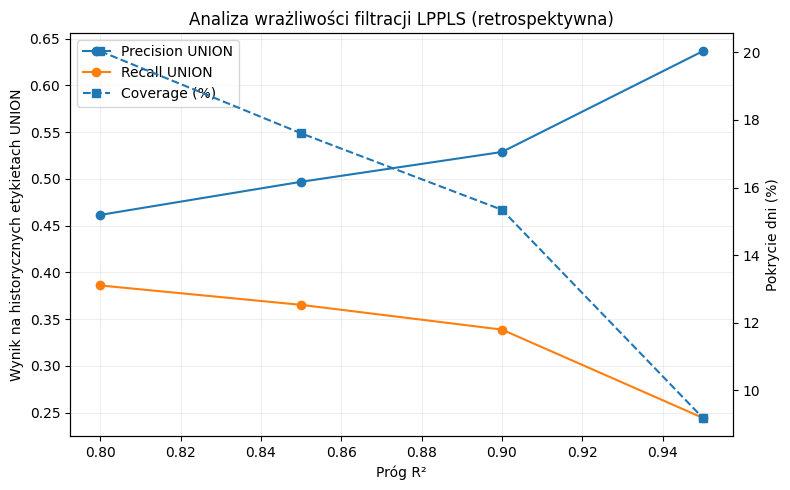

Test wielu inicjalizacji LPPLS 11_09_refit_by_seed.csv nie został dostarczony: stabilność startów NIEZWERYFIKOWANA.


In [10]:
if SOURCES["11_sensitivity"] is None:
    print("Brak 11_01_sensitivity_grid.csv — pomijam analizę filtracji.")
else:
    sensitivity=pd.read_csv(SOURCES["11_sensitivity"])
    expected={"r2_min","w_lo","w_hi","tc_max","m_lo","m_hi","accepted_windows",
              "days_with_signal","coverage_pct","precision","recall"}
    if not expected.issubset(sensitivity):
        raise ValueError("Nieznany format 11_01_sensitivity_grid.csv: "+str(expected-set(sensitivity)))
    baseline=(np.isclose(sensitivity.w_lo,6) & np.isclose(sensitivity.w_hi,13)
              & np.isclose(sensitivity.tc_max,40) & np.isclose(sensitivity.m_lo,0)
              & np.isclose(sensitivity.m_hi,1))
    r2part=sensitivity.loc[baseline].sort_values("r2_min").copy()
    r2part.to_csv(OUT / "12_15_sensitivity_R2_warz_baseline.csv",index=False)
    display(r2part[["r2_min","accepted_windows","days_with_signal","coverage_pct","precision","recall"]].round(3))
    if not r2part.empty:
        fig,ax=plt.subplots(figsize=(8,5))
        ax.plot(r2part.r2_min,r2part.precision,marker="o",label="Precision UNION")
        ax.plot(r2part.r2_min,r2part.recall,marker="o",label="Recall UNION")
        ax.set_xlabel("Próg R²");ax.set_ylabel("Wynik na historycznych etykietach UNION")
        ax2=ax.twinx()
        ax2.plot(r2part.r2_min,r2part.coverage_pct,marker="s",linestyle="--",label="Coverage (%)")
        ax2.set_ylabel("Pokrycie dni (%)")
        ax.set_title("Analiza wrażliwości filtracji LPPLS (retrospektywna)")
        l1,n1=ax.get_legend_handles_labels();l2,n2=ax2.get_legend_handles_labels()
        ax.legend(l1+l2,n1+n2,loc="best");ax.grid(alpha=.2)
        fig.tight_layout()
        fig.savefig(OUT / "12_16_R2_precision_recall_coverage.png",dpi=200)
        plt.show()
    if SOURCES["11_refit_seeds"] is None:
        print("Test wielu inicjalizacji LPPLS 11_09_refit_by_seed.csv nie został dostarczony: stabilność startów NIEZWERYFIKOWANA.")
    else:
        print("Znaleziono wyniki ponownych inicjalizacji; do osobnej interpretacji.")

## 10. Kontrole publikacyjne, raport i manifest

Zapiszemy końcowe notatki metodologiczne i manifest. **Nie określamy automatycznie „najlepszego modelu”** po przejrzeniu tych samych lat 2021–2024. Wybór modelu na tych danych byłby post-hoc.

In [11]:
checks=[]
for row in cohorts.itertuples():
    target=matched.loc[(matched.drop_pct==row.drop_pct)&(matched.horizon==row.horizon)]
    labels=target.drop_duplicates("date").sort_values("date")
    checks.append({
        "drop_pct":row.drop_pct,"horizon":row.horizon,
        "n_common_days":row.n_common_dates,
        "first_test_day":labels.date.min().strftime("%Y-%m-%d"),
        "last_test_day":labels.date.max().strftime("%Y-%m-%d"),
        "n_positive":int(labels.y_true.sum()),
        "n_negative":int((1-labels.y_true).sum()),
        "single_class_target":labels.y_true.nunique()<2,
        "few_positive_days_lt20":int(labels.y_true.sum())<20,
        "n_years":int(labels.date.dt.year.nunique()),
        "different_cohorts_by_model":row.retained_fraction<1.0,
    })
quality=pd.DataFrame(checks)
quality.to_csv(OUT / "12_17_kontrola_jakosci.csv",index=False)
display(quality)

report = [
    "# Notatnik 12 — raport z konsolidacji wyników",
    "",
    "## Zakres i uczciwe ograniczenia",
    "- Główne metryki ML: 08b, wspólne daty OOS, zadania future drop.",
    "- Event-based z 10b: osobny okres (zwykle 2022–2024) i osobna definicja drawdown.",
    "- Czułość filtracji z 11: historyczne etykiety UNION, retrospekcja.",
    "- Wyniki testowe 2021–2024 były już analizowane podczas rozwoju projektu; nie są niezależnym końcowym holdoutem.",
    "- Bootstrap blokowy jest przybliżeniem niepewności; nie uwzględnia selekcji po obejrzeniu wyników i wielokrotnych testów.",
    "- Nie wolno automatycznie wybierać zwycięzcy na podstawie porównań OOS.",
    "",
    "## Obecność plików",
]
for r in manifest.itertuples():
    report.append(f"- {r.source}: {'TAK' if r.available else 'BRAK'}")
report.extend(["","## Kontrole kohort"])
for r in quality.itertuples():
    report.append(f"- {r.drop_pct}%/{r.horizon}d: {r.n_common_days} dni, pozytywne={r.n_positive}, "
                  f"okres {r.first_test_day}–{r.last_test_day}")
report.extend(["","## Co wymaga dalszej weryfikacji przed publikacją?",
    "1. Powtórzenie oceny na rzeczywiście nowym okresie albo jawne oznaczenie wniosków jako eksploracyjnych.",
    "2. Wpływ doboru filtra LPPLS i losowych inicjalizacji estymacji na modele prognostyczne.",
    "3. Wrażliwość bootstrapu na długości bloków, próg i wybór konfiguracji (wiele porównań).",
    "4. Definicja momentu rozpoczęcia zdarzenia, cenzurowanie horyzontów i liczba niezależnych epizodów.",
])
(OUT / "12_18_raport_metodologiczny.md").write_text("\n".join(report),encoding="utf-8")
meta={
    "notebook":"12_Final_Model_Comparison_Publication_Tables",
    "description":"aggregation / no refit",
    "plot_target":{"drop_pct":PLOT_DROP,"horizon":PLOT_HORIZON},
    "bootstrap":{"reps":BOOT_REPS,"block_days":BOOT_BLOCK_DAYS,"seed":RANDOM_SEED},
    "source_filenames":{k:str(p) if p is not None else None for k,p in SOURCES.items()},
}
(OUT / "12_19_konfiguracja.json").write_text(json.dumps(meta,ensure_ascii=False,indent=2),encoding="utf-8")
print("Wyniki:",OUT.resolve())
print("Pliki:")
for p in sorted(OUT.iterdir()):
    print(" •",p.name)

,drop_pct,horizon,n_common_days,first_test_day,last_test_day,n_positive,n_negative,single_class_target,few_positive_days_lt20,n_years,different_cohorts_by_model
0,10,30,1431,2021-01-01,2024-12-01,572,859,False,False,4,False
1,10,45,1416,2021-01-01,2024-11-16,697,719,False,False,4,False
2,10,60,1401,2021-01-01,2024-11-01,764,637,False,False,4,False
3,15,30,1431,2021-01-01,2024-12-01,342,1089,False,False,4,False
4,15,45,1416,2021-01-01,2024-11-16,454,962,False,False,4,False
5,15,60,1401,2021-01-01,2024-11-01,539,862,False,False,4,False
6,20,30,1431,2021-01-01,2024-12-01,163,1268,False,False,4,False
7,20,45,1416,2021-01-01,2024-11-16,255,1161,False,False,4,False
8,20,60,1401,2021-01-01,2024-11-01,322,1079,False,False,4,False


Wyniki: C:\Users\cynar\Desktop\projects\lppls_article\wyniki_finalne_12
Pliki:
 • 12_00_manifest_zrodel.csv
 • 12_01_wspolne_daty_OOS.csv
 • 12_02_finalne_metryki_OOS.csv
 • 12_03_tabela_porownawcza_AP.csv
 • 12_04_AP_vs_prevalence.png
 • 12_05_metryki_roczne_OOS.csv
 • 12_06_roczne_delta_AP.csv
 • 12_07_roczne_delta_AP.png
 • 12_08_paired_delta_AP_blockbootstrap.csv
 • 12_09_delta_AP_z_CI.png
 • 12_10_publikacja_ablation.csv
 • 12_11_ablation_z_09.png
 • 12_12_ablation_krokowe_delta.csv
 • 12_13_event_based_publikacja_2022_2024.csv
 • 12_14_event_recall_false_warnings.png
 • 12_15_sensitivity_R2_warz_baseline.csv
 • 12_16_R2_precision_recall_coverage.png
 • 12_17_kontrola_jakosci.csv
 • 12_18_raport_metodologiczny.md
 • 12_19_konfiguracja.json


## Sugerowane użycie w artykule

**Tabela główna:** `12_03_tabela_porownawcza_AP.csv`, z jasno podaną częstością klasy pozytywnej i liczbą wspólnych dni.

**Niepewność:** `12_08_paired_delta_AP_blockbootstrap.csv` + analiza roczna `12_06_roczne_delta_AP.csv` (o ile dostępna).

**Ablation:** `12_10_publikacja_ablation.csv` (jeśli ukończono notatnik 09).

**Użyteczność operacyjna:** `12_13_event_based_publikacja_2022_2024.csv` (jeśli 10b wykonał się na rzeczywistych danych, z jawną oceną statusu kalibracji).

**Wrażliwość LPPLS:** `12_15_sensitivity_R2_warz_baseline.csv` i, jeśli są dostępne, osobno wyniki wielokrotnych estymacji z różnymi inicjalizacjami.

Zachowaj wszystkie pliki CSV i manifest SHA256 razem z kodem, wersjami pakietów oraz opisem źródła cen BTC. Wyniki należy opisać jako *retrospective chronologically evaluated* tam, gdzie dotychczasowy rozwój projektu korzystał z tych samych okresów testowych.